# 10 — Context × topology interaction

This notebook compares two ways of combining context-range probing and structured blackout.

**Independent probing**
- clean context curve: `C = (L32, L128, L256)`
- topology measured separately at `k=256`: `T`

**Composed probing**
- measure losses `L_{k,M}` for every context length `k` and blackout pattern `M`

The key question is whether the composed response surface contains information beyond simply concatenating `C` and `T`.


## Main interaction

For pattern `M` at context length `k`:

`P_M(k) = L_{k,M} - L_{k,clean}`

`T_M(k) = P_M(k) - P_random(k)`

Then define difference-in-differences:

`I_M(k1,k2) = T_M(k2) - T_M(k1)`.

If `I != 0`, the relative effect of blackout geometry changes with context scale.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, f1_score

cwd=Path.cwd().resolve()
ROOT=cwd.parent if cwd.name=="experiments" else cwd
DATA,RESULTS,FIGURES=ROOT/"data",ROOT/"results",ROOT/"figures"
RESULTS.mkdir(parents=True,exist_ok=True); FIGURES.mkdir(parents=True,exist_ok=True)

RAW_PATH=DATA/"raw"/"ghostbuster_detector_pool.parquet"
CTX_PATH=RESULTS/"ghostbuster_detector_context.parquet"
TOPO09_PATH=RESULTS/"dependency_topology_occlusion_pilot.parquet"

SCORER_NAME="Qwen/Qwen3-0.6B-Base"
PREFIX_LEN=384
CONTEXT_LENGTHS=[32,128,256]
PATTERNS=["clean","random","periodic","contiguous","near","far"]
NONRANDOM=["periodic","contiguous","near","far"]

LOCAL_KEEP=8
REMOVE_FRAC=.25
N_TARGETS=8
N_STOCHASTIC_REPS=3
SEED=1729
BATCH_SIZE=32
DEVICE="cuda" if torch.cuda.is_available() else "cpu"

print("ROOT:",ROOT)
print("device:",DEVICE)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ROOT: ..
device: cuda


## Reuse the exact notebook-09 pilot


In [2]:
raw=pd.read_parquet(RAW_PATH).copy()
ctx=pd.read_parquet(CTX_PATH).copy()

if TOPO09_PATH.exists():
    ids=set(pd.read_parquet(TOPO09_PATH)["row_id"])
    pilot=raw[raw["row_id"].isin(ids)].copy()
    pilot=pilot.merge(
        ctx[["row_id","context_loss_8","context_loss_32","context_loss_128","context_loss_256"]],
        on="row_id",how="inner",validate="one_to_one")
    pilot["group_key"]=pilot["domain"].astype(str)+"::"+pilot["group_id"].astype(str)
else:
    pool=raw[raw["generator"].isin(["human","gpt","claude"])].copy()
    pool["group_key"]=pool["domain"].astype(str)+"::"+pool["group_id"].astype(str)
    good=(pool.groupby("group_key")["generator"].agg(["size","nunique"])
          .query("size==3 and nunique==3").index)
    pool=pool[pool["group_key"].isin(good)].copy()
    pool=pool.merge(
        ctx[["row_id","context_loss_8","context_loss_32","context_loss_128","context_loss_256"]],
        on="row_id",how="inner",validate="one_to_one")
    good=(pool.groupby("group_key")["generator"].agg(["size","nunique"])
          .query("size==3 and nunique==3").index)
    pool=pool[pool["group_key"].isin(good)].copy()
    rng=np.random.default_rng(SEED); chosen=[]
    for d in sorted(pool["domain"].unique()):
        ks=np.array(sorted(pool.loc[pool["domain"]==d,"group_key"].unique()))
        chosen.extend(rng.choice(ks,size=50,replace=False).tolist())
    pilot=pool[pool["group_key"].isin(chosen)].copy()

pilot=pilot.sort_values(["domain","group_key","generator"]).reset_index(drop=True)
print("groups:",pilot["group_key"].nunique(),"docs:",len(pilot))
display(pilot.groupby(["domain","generator"]).size())


groups: 150 docs: 450


domain  generator
essay   claude       50
        gpt          50
        human        50
reuter  claude       50
        gpt          50
        human        50
wp      claude       50
        gpt          50
        human        50
dtype: int64

## Load scorer


In [3]:
tokenizer=AutoTokenizer.from_pretrained(SCORER_NAME)
dtype=torch.bfloat16 if DEVICE=="cuda" else torch.float32
model=AutoModelForCausalLM.from_pretrained(SCORER_NAME,dtype=dtype).to(DEVICE)
model.eval()
print("loaded",SCORER_NAME)


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 12484.01it/s]


loaded Qwen/Qwen3-0.6B-Base


## Scale-matched blackout operators


In [4]:
PATTERN_SEEDS={"random":101,"periodic":211,"contiguous":307,"near":401,"far":503}

def removal_budget(k):
    return int(round(REMOVE_FRAC*(k-LOCAL_KEEP)))

def remove_by_indices(distant,idx):
    idx=set(int(i) for i in idx)
    return torch.stack([tok for i,tok in enumerate(distant) if i not in idx])

def occlude_context(context_ids,pattern,rng):
    k=len(context_ids)
    if pattern=="clean":
        return context_ids.clone()
    distant=context_ids[:-LOCAL_KEEP]
    local=context_ids[-LOCAL_KEEP:]
    n=len(distant); m=removal_budget(k)

    if pattern=="random":
        idx=rng.choice(n,size=m,replace=False)
    elif pattern=="periodic":
        idx=np.linspace(0,n-1,m,dtype=int)
    elif pattern=="contiguous":
        start=int(rng.integers(0,n-m+1)); idx=np.arange(start,start+m)
    elif pattern=="near":
        idx=np.arange(n-m,n)
    elif pattern=="far":
        idx=np.arange(0,m)
    else:
        raise ValueError(pattern)

    out=torch.cat([remove_by_indices(distant,idx),local],dim=0)
    assert torch.equal(out[-LOCAL_KEEP:],local)
    return out

for k in CONTEXT_LENGTHS:
    toy=torch.arange(k)
    print("k",k,"remove",removal_budget(k))
    for p in PATTERNS:
        out_ids=occlude_context(toy,p,np.random.default_rng(1))
        expected=k if p=="clean" else k-removal_budget(k)
        assert len(out_ids)==expected
print("sanity passed")


k 32 remove 6
k 128 remove 30
k 256 remove 62
sanity passed


## Frozen target positions and condition scoring


In [5]:
def target_positions(ids):
    if len(ids)-max(CONTEXT_LENGTHS) < N_TARGETS:
        return None
    return np.unique(np.linspace(max(CONTEXT_LENGTHS),len(ids)-1,N_TARGETS,dtype=int))

@torch.inference_mode()
def score_batch(seqs,targets):
    losses=[]
    for start in range(0,len(seqs),BATCH_SIZE):
        xb=torch.stack(seqs[start:start+BATCH_SIZE]).to(DEVICE)
        y=torch.stack(targets[start:start+BATCH_SIZE]).to(DEVICE)
        logits=model(input_ids=xb,logits_to_keep=1).logits[:,-1,:].float()
        logp=torch.log_softmax(logits,dim=-1)
        nll=-logp[torch.arange(len(y),device=DEVICE),y]
        losses.extend(nll.cpu().numpy().tolist())
    return np.asarray(losses,float)

def score_condition(text,k,pattern,row_seed):
    ids=tokenizer(str(text),add_special_tokens=False,return_tensors="pt")["input_ids"][0][:PREFIX_LEN]
    posns=target_positions(ids)
    if posns is None: return np.nan,np.nan

    reps=N_STOCHASTIC_REPS if pattern in {"random","contiguous"} else 1
    means=[]
    for rep in range(reps):
        off=0 if pattern=="clean" else PATTERN_SEEDS[pattern]
        rng=np.random.default_rng(row_seed+10007*rep+997*k+off)
        seqs=[]; targets=[]
        for pos in posns:
            context=ids[pos-k:pos]
            seqs.append(occlude_context(context,pattern,rng))
            targets.append(ids[pos])
        means.append(score_batch(seqs,targets).mean())

    sd=float(np.std(means,ddof=1)) if len(means)>1 else 0.0
    return float(np.mean(means)),sd


## Run the 3 × 6 context-topology grid


In [6]:
rows=[]
for i,r in enumerate(tqdm(pilot.itertuples(index=False),total=len(pilot),desc="Context x topology")):
    rec={"row_id":r.row_id,"group_key":r.group_key,"domain":r.domain,"generator":r.generator}
    for k in CONTEXT_LENGTHS:
        for p in PATTERNS:
            loss,sd=score_condition(r.text,k,p,SEED+i*1000003)
            rec[f"L_{k}_{p}"]=loss
            rec[f"L_{k}_{p}_sd"]=sd
    rows.append(rec)

grid=pd.DataFrame(rows)
grid.to_parquet(RESULTS/"context_topology_interaction_grid.parquet",index=False)
display(grid.head())


Context x topology: 100%|█████████████████████████████████████████████████████████████████████████████| 450/450 [14:05<00:00,  1.88s/it]


,row_id,group_key,domain,generator,L_32_clean,L_32_clean_sd,L_32_random,L_32_random_sd,L_32_periodic,L_32_periodic_sd,...,L_256_random,L_256_random_sd,L_256_periodic,L_256_periodic_sd,L_256_contiguous,L_256_contiguous_sd,L_256_near,L_256_near_sd,L_256_far,L_256_far_sd
0,claude_eval::essay::claude::124,essay::124,essay,claude,1.052942,0.0,2.172604,0.469915,1.538123,0.0,...,1.466242,0.071453,1.824439,0.0,0.926635,0.071710,2.620993,0.0,0.999803,0.0
1,original::essay::gpt::124,essay::124,essay,gpt,3.144529,0.0,3.328506,0.185101,3.464804,0.0,...,1.806868,0.210151,2.040680,0.0,1.575126,0.119392,2.873291,0.0,1.427149,0.0
2,original::essay::human::124,essay::124,essay,human,2.471988,0.0,2.681747,0.197702,2.605083,0.0,...,2.078437,0.069066,2.400235,0.0,2.172542,0.116469,2.450475,0.0,2.336866,0.0
3,claude_eval::essay::claude::129,essay::129,essay,claude,0.957983,0.0,1.239981,0.060684,1.809423,0.0,...,1.188573,0.142004,1.912739,0.0,0.652275,0.033623,0.834461,0.0,0.653306,0.0
4,original::essay::gpt::129,essay::129,essay,gpt,0.568828,0.0,0.901991,0.020104,0.795596,0.0,...,0.772473,0.179996,1.118922,0.0,0.309796,0.016929,0.794995,0.0,0.219336,0.0


## Derive topology-at-scale and explicit interactions


In [7]:
feat=grid.copy()

for k in CONTEXT_LENGTHS:
    for p in ["random",*NONRANDOM]:
        feat[f"P_{k}_{p}"]=feat[f"L_{k}_{p}"]-feat[f"L_{k}_clean"]
    for p in NONRANDOM:
        feat[f"T_{k}_{p}"]=feat[f"P_{k}_{p}"]-feat[f"P_{k}_random"]

for p in NONRANDOM:
    feat[f"I_32_128_{p}"]=feat[f"T_128_{p}"]-feat[f"T_32_{p}"]
    feat[f"I_128_256_{p}"]=feat[f"T_256_{p}"]-feat[f"T_128_{p}"]
    feat[f"I_32_256_{p}"]=feat[f"T_256_{p}"]-feat[f"T_32_{p}"]

feat.to_parquet(RESULTS/"context_topology_interaction_features.parquet",index=False)


## Inspect context-dependent topology profiles


In [8]:
rows=[]
for g in ["human","gpt","claude"]:
    s=feat[feat["generator"]==g]
    for k in CONTEXT_LENGTHS:
        for p in NONRANDOM:
            v=s[f"T_{k}_{p}"].dropna()
            rows.append({"generator":g,"k":k,"pattern":p,
                         "mean":v.mean(),"median":v.median(),"std":v.std(ddof=1),"n":len(v)})
topology_by_k=pd.DataFrame(rows)
display(topology_by_k)
topology_by_k.to_csv(RESULTS/"context_topology_profiles_by_generator.csv",index=False)


,generator,k,pattern,mean,median,std,n
0,human,32,periodic,0.037092,0.028790,0.228466,141
1,human,32,contiguous,-0.048239,-0.054350,0.185416,141
2,human,32,near,0.078164,0.064655,0.280147,141
3,human,32,far,-0.122406,-0.141507,0.234997,141
4,human,128,periodic,0.088860,0.053327,0.301040,141
5,human,128,contiguous,-0.215240,-0.229232,0.277521,141
6,human,128,near,0.191153,0.115350,0.490250,141
7,human,128,far,-0.276358,-0.260958,0.283727,141
8,human,256,periodic,0.129941,0.102421,0.274950,141
9,human,256,contiguous,-0.286923,-0.263787,0.291895,141


## Matched generator contrasts on interaction features


In [9]:
I_COLS=[f"I_{span}_{p}" for span in ["32_128","128_256","32_256"] for p in NONRANDOM]
rows=[]
for f in I_COLS:
    w=feat.pivot(index=["domain","group_key"],columns="generator",values=f).dropna()
    for a,b in [("gpt","human"),("claude","human"),("claude","gpt")]:
        d=w[a]-w[b]; sd=d.std(ddof=1)
        rows.append({"feature":f,"contrast":f"{a}-{b}","n_groups":len(d),
                     "mean_diff":d.mean(),"median_diff":d.median(),
                     "paired_dz":d.mean()/sd if sd>0 else np.nan,
                     "positive_fraction":(d>0).mean()})
interaction_contrasts=pd.DataFrame(rows)
display(interaction_contrasts)
interaction_contrasts.to_csv(RESULTS/"context_topology_interaction_matched_contrasts.csv",index=False)


,feature,contrast,n_groups,mean_diff,median_diff,paired_dz,positive_fraction
0,I_32_128_periodic,gpt-human,139,-0.002961,-0.000536,-0.006227,0.489209
1,I_32_128_periodic,claude-human,139,0.030499,0.046396,0.065549,0.575540
2,I_32_128_periodic,claude-gpt,139,0.033460,-0.006195,0.072433,0.489209
3,I_32_128_contiguous,gpt-human,139,-0.075414,-0.062635,-0.164492,0.446043
4,I_32_128_contiguous,claude-human,139,-0.039383,-0.028932,-0.091894,0.460432
5,I_32_128_contiguous,claude-gpt,139,0.036032,0.022254,0.083721,0.532374
6,I_32_128_near,gpt-human,139,-0.067673,-0.038606,-0.089589,0.453237
7,I_32_128_near,claude-human,139,-0.020959,-0.100117,-0.026197,0.460432
8,I_32_128_near,claude-gpt,139,0.046714,0.038365,0.064540,0.532374
9,I_32_128_far,gpt-human,139,-0.042028,-0.082212,-0.094338,0.424460


# Independent components vs composed probing

For GPT-vs-Claude attribution compare:

- `B+C`
- `B+T`
- `B+C+T`
- `B+CT`: full composed losses `L_{k,M}`
- `B+C+T+I`: separate main effects plus explicit difference-in-differences interactions

The decisive comparisons are `B+CT` vs `B+C+T` and `B+C+T+I` vs `B+C+T`.


In [10]:
analysis=feat.merge(ctx[["row_id","context_loss_8"]],on="row_id",how="left",validate="one_to_one")
analysis=analysis[analysis["generator"].isin(["gpt","claude"])].copy()
analysis["label"]=(analysis["generator"]=="claude").astype(int)

B=["context_loss_8"]
C=["L_32_clean","L_128_clean","L_256_clean"]
T=[f"T_256_{p}" for p in NONRANDOM]
CT=[f"L_{k}_{p}" for k in CONTEXT_LENGTHS for p in PATTERNS]
I=I_COLS

SETS={
    "B":B,
    "B+C":[*B,*C],
    "B+T":[*B,*T],
    "B+C+T":[*B,*C,*T],
    "B+CT":[*B,*CT],
    "B+C+T+I":[*B,*C,*T,*I],
}

need=sorted(set(sum(SETS.values(),[])))
analysis=analysis.dropna(subset=need).copy()

def clf():
    return Pipeline([
        ("scale",StandardScaler()),
        ("clf",LogisticRegression(class_weight="balanced",solver="lbfgs",max_iter=5000,random_state=0))
    ])

groups=np.array(sorted(analysis["group_key"].unique()))
rows=[]
for seed in range(20):
    rng=np.random.RandomState(seed); perm=rng.permutation(len(groups)); cut=int(.8*len(groups))
    trk=set(groups[perm[:cut]]); tek=set(groups[perm[cut:]])
    tr=analysis[analysis["group_key"].isin(trk)]
    te=analysis[analysis["group_key"].isin(tek)]
    for name,cols in SETS.items():
        m=clf(); m.fit(tr[cols],tr["label"])
        p=m.predict_proba(te[cols])[:,1]
        pred=(p>=.5).astype(int); y=te["label"].to_numpy()
        rows.append({"seed":seed,"method":name,
                     "auroc":roc_auc_score(y,p),
                     "balanced_accuracy":balanced_accuracy_score(y,pred),
                     "f1":f1_score(y,pred)})
attrib=pd.DataFrame(rows)
display(attrib.groupby("method")[["auroc","balanced_accuracy","f1"]].mean().sort_values("auroc",ascending=False))
attrib.to_csv(RESULTS/"context_topology_interaction_attribution_splits.csv",index=False)


,auroc,balanced_accuracy,f1
method,,,
B+C+T,0.641941,0.625191,0.620008
B+CT,0.630940,0.600634,0.587292
B+C,0.627141,0.616636,0.614181
B+C+T+I,0.612504,0.589701,0.579867
B+T,0.600096,0.588444,0.579509
B,0.559477,0.540593,0.549317


In [11]:
def ds(df,a,b,metric="auroc"):
    w=df.pivot(index="seed",columns="method",values=metric)
    v=(w[a]-w[b]).to_numpy()
    return {"comparison":f"{a} vs {b}","metric":metric,
            "mean_delta":v.mean(),"median_delta":np.median(v),
            "q25":np.quantile(v,.25),"q75":np.quantile(v,.75),
            "min":v.min(),"max":v.max(),"positive":int((v>0).sum()),"n":len(v)}

comparisons=[
    ("B+C+T","B+C"),
    ("B+C+T","B+T"),
    ("B+CT","B+C+T"),
    ("B+C+T+I","B+C+T"),
    ("B+CT","B+C"),
    ("B+C+T+I","B+C"),
]
rows=[]
for a,b in comparisons:
    for metric in ["auroc","balanced_accuracy","f1"]:
        rows.append(ds(attrib,a,b,metric))
delta_table=pd.DataFrame(rows)
display(delta_table)
delta_table.to_csv(RESULTS/"context_topology_interaction_attribution_deltas.csv",index=False)


,comparison,metric,mean_delta,median_delta,q25,q75,min,max,positive,n
0,B+C+T vs B+C,auroc,0.014799,0.012069,0.000198,0.041369,-0.107143,0.122222,15,20
1,B+C+T vs B+C,balanced_accuracy,0.008555,0.009036,-0.021121,0.039881,-0.087037,0.083333,11,20
2,B+C+T vs B+C,f1,0.005827,0.005519,-0.031884,0.032653,-0.099930,0.123774,10,20
3,B+C+T vs B+T,auroc,0.041845,0.053229,0.004023,0.088295,-0.114286,0.159770,15,20
4,B+C+T vs B+T,balanced_accuracy,0.036747,0.036686,-0.000319,0.085201,-0.066667,0.119048,14,20
5,B+C+T vs B+T,f1,0.040499,0.024098,0.005462,0.087839,-0.109630,0.150446,15,20
6,B+CT vs B+C+T,auroc,-0.011001,-0.013133,-0.024202,0.002024,-0.049425,0.032184,6,20
7,B+CT vs B+C+T,balanced_accuracy,-0.024557,-0.033333,-0.049713,-0.011607,-0.069048,0.051149,2,20
8,B+CT vs B+C+T,f1,-0.032716,-0.041263,-0.062917,-0.008328,-0.113978,0.074798,2,20
9,B+C+T+I vs B+C+T,auroc,-0.029437,-0.023356,-0.043981,-0.012599,-0.108046,0.006897,2,20


## Visualize topology curves


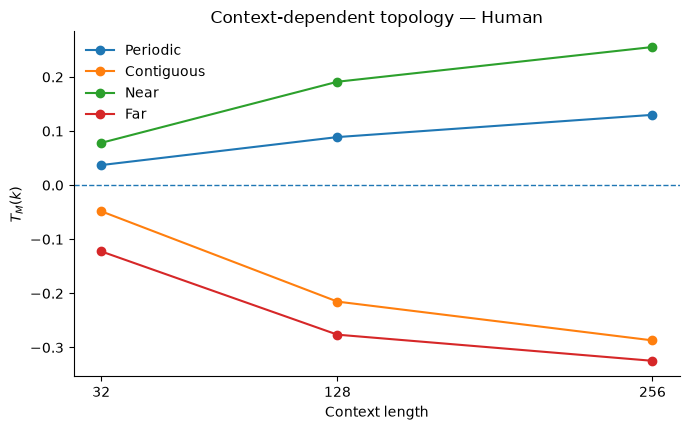

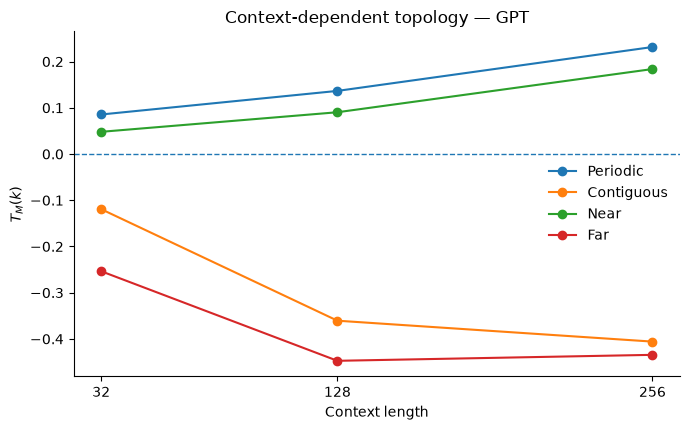

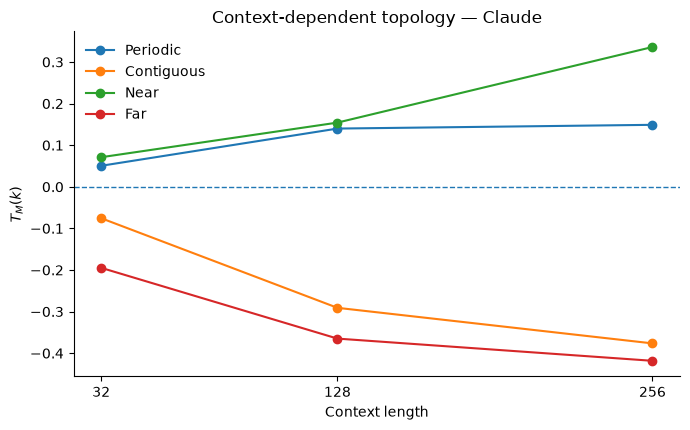

In [12]:
for g in ["human","gpt","claude"]:
    s=topology_by_k[topology_by_k["generator"]==g]
    fig,ax=plt.subplots(figsize=(7,4.4))
    for p in NONRANDOM:
        z=s[s["pattern"]==p]
        ax.plot(z["k"],z["mean"],marker="o",label=p.capitalize())
    ax.axhline(0,linestyle="--",linewidth=1)
    ax.set_xticks(CONTEXT_LENGTHS)
    ax.set_xlabel("Context length")
    ax.set_ylabel(r"$T_M(k)$")
    ax.set_title(f"Context-dependent topology — {g.upper() if g=='gpt' else g.capitalize()}")
    ax.legend(frameon=False)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(FIGURES/f"context_topology_profile_{g}.pdf",bbox_inches="tight")
    fig.savefig(FIGURES/f"context_topology_profile_{g}.png",dpi=200,bbox_inches="tight")
    plt.show()


## Interpretation

The strongest result is:

`B+CT > B+C+T`

because that means measuring range and topology separately is insufficient; extra source information appears only when context length is measured **on perturbed text**.

A second clean result is:

`B+C+T+I > B+C+T`

showing that explicit range×topology interaction features add information beyond both main effects.

If neither is positive, the composed probe is not worth extra compute. If either is positive, the next robustness step should be a length-preserving perturbation.


In [13]:
def fs(x): return f"{x:+.5f}"

print("KEY GPT-vs-CLAUDE COMPARISONS")
for a,b in [("B+C+T","B+C"),("B+CT","B+C+T"),("B+C+T+I","B+C+T"),("B+CT","B+C")]:
    r=delta_table[(delta_table["comparison"]==f"{a} vs {b}")&
                  (delta_table["metric"]=="auroc")].iloc[0]
    print(f"{a} - {b}",
          "| mean",fs(r.mean_delta),
          "| median",fs(r.median_delta),
          "| IQR",f"[{fs(r.q25)}, {fs(r.q75)}]",
          "| positive",f"{int(r.positive)}/{int(r.n)}")


KEY GPT-vs-CLAUDE COMPARISONS
B+C+T - B+C | mean +0.01480 | median +0.01207 | IQR [+0.00020, +0.04137] | positive 15/20
B+CT - B+C+T | mean -0.01100 | median -0.01313 | IQR [-0.02420, +0.00202] | positive 6/20
B+C+T+I - B+C+T | mean -0.02944 | median -0.02336 | IQR [-0.04398, -0.01260] | positive 2/20
B+CT - B+C | mean +0.00380 | median +0.01667 | IQR [-0.02030, +0.03810] | positive 12/20
